In [10]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
demographics = pd.read_csv('data/demographic_primary_vote_sep2026.csv')
topline = pd.read_csv('data/topline_primary_vote.csv')

In [12]:
topline

,Poll,Labor,Greens,Others,One Nation,L/NP
0,Nov 23 Election,36.6,11.5,17.0,0.4,34.5
1,Feb 26,23.0,15.0,12.0,21.0,29.0
2,June 26,21.0,15.0,11.0,23.0,30.0
3,August 26,23.0,13.0,10.0,22.0,32.0
4,Sep 26,25.0,14.0,11.0,20.0,30.0


In [13]:
demographics

,Demographic,Labor,Greens,Others,One Nation,L/NP
0,Male,24,12,13,19,32
1,Female,25,16,10,22,27
2,18-34,29,23,9,16,23
3,35-54,24,16,11,20,29
4,55+,22,7,13,23,35
5,School Education,27,14,12,21,26
6,TAFE Education,26,10,6,28,30
7,University Education,21,18,14,13,34
8,Own Home Outright,23,10,12,17,38
9,Mortgage Holder,25,14,9,23,29


In [14]:
class demogCat:

    def __init__(
            self, 
            name:str,
            columns: list[str], 
            data = pd.DataFrame, 
            rescale_to_pop: bool = True
        ):
        self.name = name
        self.columns = columns
        self.rescale_to_pop = rescale_to_pop

        if self.rescale_to_pop:
            self.data = rescale_to_population(data)
        else:
            self.data = data

    def get_totals(self) -> np.ndarray:
        return self.data.to_numpy().sum(axis=0)

    def get_columns(self) -> list[str]:
        return self.columns

    def get_demog_data(self) -> np.ndarray:
        return self.data[self.columns]

def calc_party_shares(demographics: pd.DataFrame, parties: list[str]) -> pd.DataFrame:
    pct = demographics.set_index('Demographic')[parties].to_numpy() / 100
    return pd.DataFrame(pct, index=demographics.Demographic, columns=parties)

    

In [15]:
from utils.census import (
    get_census_education_data,
    get_census_age_data,
    get_census_income_data,
    get_census_language_data,
    get_census_sex_data,
    get_census_tenure_data,
    rescale_to_population
)

SEDS  = sorted(set(get_census_education_data().index) - {'SED29494', 'SED29797'})
SEX   = ['Male', 'Female']
AGE   = ['18-34', '35-54', '55+']
LANGUAGE = ['Other Language at Home', 'English Only']
INCOME = ['<$45K','$45-125K','$125K+']
TENURE = ['Own Home Outright', 'Mortgage Holder','Renter']
EDUCATION = ['School Education','University Education','TAFE Education']
PARTY = ['Labor', 'Greens', 'Others', 'One Nation', 'L/NP']

POLL_DATE = "Sep 26"

education_data = demogCat(
    name = "education",
    columns=EDUCATION,
    data=get_census_education_data()
)
age_data = demogCat(
    name = "age",
    columns = AGE,
    data=get_census_age_data()
)
income_data = demogCat(
    name="income",
    columns = INCOME,
    data=get_census_income_data()
)
language_data = demogCat(
    name = "language",
    columns=LANGUAGE,
    data=get_census_language_data()
)
sex_data = demogCat(
    name = "sex",
    columns=SEX,
    data=get_census_sex_data()
)
tenure_data = demogCat(
    name = "tenure",
    columns=TENURE,
    data=get_census_tenure_data()
)
DEMOGS = [
    education_data, 
    age_data, 
    income_data, 
    language_data, 
    sex_data, 
    tenure_data
]


In [16]:
def run_ipf(
        original_matrix: np.ndarray,
        row_col_totals: list[np.ndarray],
        dimensions: list[list[int]],
        convergence_rate: float = 1.0e-10
        ) -> np.ndarray:
    return ipfn.ipfn(
        original = original_matrix,
        aggregates = row_col_totals,
        dimensions = dimensions,
        convergence_rate=convergence_rate
    ).iteration()


In [17]:
topline

,Poll,Labor,Greens,Others,One Nation,L/NP
0,Nov 23 Election,36.6,11.5,17.0,0.4,34.5
1,Feb 26,23.0,15.0,12.0,21.0,29.0
2,June 26,21.0,15.0,11.0,23.0,30.0
3,August 26,23.0,13.0,10.0,22.0,32.0
4,Sep 26,25.0,14.0,11.0,20.0,30.0


In [18]:
from ipfn import ipfn

pct = calc_party_shares(demographics, parties=PARTY)

# we rescale all to 18+ population, so any choice works
total_pop = education_data.get_totals().sum()
topline_p = total_pop * topline.set_index('Poll').loc[POLL_DATE, PARTY].to_numpy() / 100 # population counts per party

ipf_mats = dict()
for demog in DEMOGS:
    print(f"Running: {demog.name}...")
    ipf_mats[demog.name]= run_ipf(
        original_matrix = pct.loc[demog.get_columns()].to_numpy(dtype=float, copy=True),
        row_col_totals = [demog.get_totals(), topline_p],
        dimensions =[[0], [1]],
    )


Running: education...
ipfn converged: convergence_rate not updating or below rate_tolerance
Running: age...
ipfn converged: convergence_rate not updating or below rate_tolerance
Running: income...
ipfn converged: convergence_rate not updating or below rate_tolerance
Running: language...
ipfn converged: convergence_rate not updating or below rate_tolerance
Running: sex...
ipfn converged: convergence_rate not updating or below rate_tolerance
Running: tenure...
ipfn converged: convergence_rate not updating or below rate_tolerance


In [65]:
gpd.read_file('./data/spatial/SED_2021_AUST_GDA2020_SHP/SED_2021_AUST_GDA2020.shp')

,SED_CODE21,SED_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,SHAPE_Leng,SHAPE_Area,geometry
0,10001,Albury,1,New South Wales,AUS,Australia,19684.1233,http://linked.data.gov.au/dataset/asgsed3/SED2...,14.780900,1.959188,"POLYGON ((147.05838 -36.08631, 147.05869 -36.0..."
1,10002,Auburn,1,New South Wales,AUS,Australia,38.4245,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.316897,0.003743,"POLYGON ((151.04269 -33.88751, 151.03965 -33.8..."
2,10003,Ballina,1,New South Wales,AUS,Australia,1050.7719,http://linked.data.gov.au/dataset/asgsed3/SED2...,2.360459,0.097039,"MULTIPOLYGON (((153.60762 -28.82836, 153.60761..."
3,10004,Balmain,1,New South Wales,AUS,Australia,13.2658,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.283432,0.001293,"POLYGON ((151.19142 -33.8847, 151.19121 -33.88..."
4,10005,Bankstown,1,New South Wales,AUS,Australia,27.2579,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.284281,0.002657,"POLYGON ((151.01554 -33.87974, 151.01615 -33.8..."
...,...,...,...,...,...,...,...,...,...,...,...
447,89797,Migratory - Offshore - Shipping (ACT),8,Australian Capital Territory,AUS,Australia,0.0000,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.000000,0.000000,None
448,99191,Unclassified (OT),9,Other Territories,AUS,Australia,255.7420,http://linked.data.gov.au/dataset/asgsed3/SED2...,3.153478,0.022613,"MULTIPOLYGON (((96.84195 -12.2034, 96.84196 -1..."
449,99494,No usual address (OT),9,Other Territories,AUS,Australia,0.0000,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.000000,0.000000,None
450,99797,Migratory - Offshore - Shipping (OT),9,Other Territories,AUS,Australia,0.0000,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.000000,0.000000,None


In [89]:
electorate_boundaries_2021 = (
    gpd.read_file('./data/spatial/SED_2021_AUST_GDA2020_SHP/SED_2021_AUST_GDA2020.shp')
    .query("STE_NAME21 == 'Victoria'")
    .assign(district = lambda x: x['SED_NAME21'].replace(r"\s\((?<=\().*?(?=\))\)", "", regex=True).str.strip().str.upper())
    # .loc[:, ['SED_CODE21', 'district']]
)
electorate_boundaries_2022 = (
    gpd.read_file('./data/spatial/ll_gda2020/esrishape/whole_of_dataset/victoria/VMADMIN/STATE_ASSEMBLY_2022.shp')
)


In [92]:
electorate_boundaries_2021.crs == electorate_boundaries_2022.crs

True

In [104]:
electorate_boundaries_2022["area_2022"] = electorate_boundaries_2022.to_crs(electorate_boundaries_2022.crs).geometry.area

C:\Users\61417\AppData\Local\Temp\ipykernel_23460\2721100227.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  electorate_boundaries_2022["area_2022"] = electorate_boundaries_2022.to_crs(electorate_boundaries_2022.crs).geometry.area


In [ ]:
def calculate_2021_to_2022_mapping(
        electorate_boundaries_2021: gpd.GeoDataFrame,
        electorate_boundaries_2022: gpd.GeoDataFrame,
) -> pd.DataFrame:
    electorate_boundaries_2022["area_2022"] = electorate_boundaries_2022.to_crs(electorate_boundaries_2022.crs).geometry.area
    electorate_intersection = gpd.overlay(electorate_boundaries_2022, electorate_boundaries_2021, how = "intersection", keep_geom_type=False)
    electorate_intersection["overlap_area"] = electorate_intersection.geometry.to_crs(electorate_boundaries_2022.crs).area
    electorate_intersection["overlap_proportion"] = (
        electorate_intersection["overlap_area"] / electorate_intersection["area_2022"]
    )
    ## renormalise overlap proportion due to odd coastline boundary issues
    electorate_intersection["overlap_proportion"] = (
        electorate_intersection["overlap_proportion"] / electorate_intersection.groupby('DISTRICT')['overlap_proportion'].transform("sum")
    )
    return electorate_intersection.loc[:, ['DISTRICT', "SED_CODE21", "overlap_proportion"]]

In [111]:
electorate_intersection = gpd.overlay(electorate_boundaries_2022, electorate_boundaries_2021, how = "intersection", keep_geom_type=False)
electorate_intersection["overlap_area"] = electorate_intersection.geometry.to_crs(electorate_boundaries_2022.crs).area
electorate_intersection["overlap_proportion"] = (
    electorate_intersection["overlap_area"] / electorate_intersection["area_2022"]
)
## renormalise overlap proportion due to odd coastline boundary issues
electorate_intersection["overlap_proportion"] = electorate_intersection["overlap_proportion"] / electorate_intersection.groupby('DISTRICT')['overlap_proportion'].transform("sum")
electorate_intersection.head()

C:\Users\61417\AppData\Local\Temp\ipykernel_23460\2947396970.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  electorate_intersection["overlap_area"] = electorate_intersection.geometry.to_crs(electorate_boundaries_2022.crs).area


,UFI,DISTRICTC,DISTRICT,DIST_LABEL,REGIONC,REGION,REG_LABEL,UFI_CR,area_2022,SED_CODE21,...,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,SHAPE_Leng,SHAPE_Area,district,geometry,overlap_area,overlap_proportion
0,21992881,3,BASS,Bass District,1,EASTERN VICTORIA,Eastern Victoria Region,2021-11-19,0.14001,20302,...,AUS,Australia,1397.6328,http://linked.data.gov.au/dataset/asgsed3/SED2...,4.127270,0.144109,BASS,"MULTIPOLYGON (((145.33317 -38.49817, 145.33318...",0.128490,0.918903
1,21992881,3,BASS,Bass District,1,EASTERN VICTORIA,Eastern Victoria Region,2021-11-19,0.14001,22105,...,AUS,Australia,80.0936,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.401628,0.008227,CRANBOURNE,"MULTIPOLYGON (((145.2288 -38.14586, 145.23207 ...",0.000002,0.000016
2,21992881,3,BASS,Bass District,1,EASTERN VICTORIA,Eastern Victoria Region,2021-11-19,0.14001,23602,...,AUS,Australia,7265.8576,http://linked.data.gov.au/dataset/asgsed3/SED2...,14.670545,0.749996,GIPPSLAND SOUTH,"MULTIPOLYGON (((145.71757 -38.28766, 145.71699...",0.000020,0.000143
3,21992881,3,BASS,Bass District,1,EASTERN VICTORIA,Eastern Victoria Region,2021-11-19,0.14001,23702,...,AUS,Australia,474.1413,http://linked.data.gov.au/dataset/asgsed3/SED2...,2.431871,0.048815,HASTINGS,"POLYGON ((145.43028 -38.21501, 145.43006 -38.2...",0.011304,0.080845
4,21992881,3,BASS,Bass District,1,EASTERN VICTORIA,Eastern Victoria Region,2021-11-19,0.14001,25802,...,AUS,Australia,4442.6219,http://linked.data.gov.au/dataset/asgsed3/SED2...,4.548367,0.455656,NARRACAN,"MULTIPOLYGON (((145.55859 -38.15613, 145.55901...",0.000013,0.000094


In [119]:
rescale_to_population(get_census_education_data()).reset_index().rename(columns={"SED_CODE2021": "SED_CODE21"})

,SED_CODE_2021,School Education,University Education,TAFE Education
0,SED20106,15931.976472,40624.676485,14819.347043
1,SED20207,26288.823548,31179.164661,21851.011792
2,SED20302,32954.810447,20970.444267,32741.745286
3,SED20401,18404.255512,15166.479816,17699.264672
4,SED20508,19965.066183,15522.317470,21607.616347
...,...,...,...,...
83,SED28408,19182.199467,13584.802929,16340.997603
84,SED28507,26575.193530,18595.716850,22078.089620
85,SED28607,17817.789044,25577.097117,14268.113840
86,SED28704,25840.988860,19391.666377,28437.344763


In [121]:
electorate_intersection.loc[:, ['DISTRICT', "SED_CODE21", "overlap_proportion"]]

,DISTRICT,SED_CODE21,overlap_proportion
0,BASS,20302,9.189025e-01
1,BASS,22105,1.593837e-05
2,BASS,23602,1.428792e-04
3,BASS,23702,8.084459e-02
4,BASS,25802,9.405847e-05
...,...,...,...
508,SYDENHAM,24808,4.654254e-04
509,SYDENHAM,26207,8.624973e-08
510,SYDENHAM,27807,5.798412e-04
511,SYDENHAM,27907,2.278181e-04


In [141]:
test_df = (
    rescale_to_population(
        get_census_education_data()
    )
    .reset_index()
    # .rename(columns={"SED_CODE_2021": "SED_CODE21"})
    .assign(SED_CODE21 = lambda x: x["SED_CODE_2021"].replace(r"^SED", "", regex=True))
)
test_df

,SED_CODE_2021,School Education,University Education,TAFE Education,SED_CODE21
0,SED20106,15931.976472,40624.676485,14819.347043,20106
1,SED20207,26288.823548,31179.164661,21851.011792,20207
2,SED20302,32954.810447,20970.444267,32741.745286,20302
3,SED20401,18404.255512,15166.479816,17699.264672,20401
4,SED20508,19965.066183,15522.317470,21607.616347,20508
...,...,...,...,...,...
83,SED28408,19182.199467,13584.802929,16340.997603,28408
84,SED28507,26575.193530,18595.716850,22078.089620,28507
85,SED28607,17817.789044,25577.097117,14268.113840,28607
86,SED28704,25840.988860,19391.666377,28437.344763,28704


In [ ]:
def map_2021_census_to_2022_electorates(
        mapping_2021_to_2022: pd.DataFrame,
        demog_df: pd.DataFrame,
        columns: str
    ) -> pd.DataFrame:
    return (
        mapping_2021_to_2022
        .merge(
            demog_df,
            on="SED_CODE21"
        )
        .assign(
            **{
                col: lambda x, col=col: x[col] * x["overlap_proportion"] 
                for col in columns
            }
        )
        .groupby("DISTRICT")
        .sum()[columns]
    )

In [150]:
(
    electorate_intersection.loc[:, ['DISTRICT', "SED_CODE21", "overlap_proportion"]]
    .merge(
        test_df,
        on="SED_CODE21"
    )
    .assign(
        **{
            col: lambda x, col=col: x[col] * x["overlap_proportion"] 
            for col in EDUCATION
        }
    )
    .groupby("DISTRICT")
    .sum()[EDUCATION]

)

,School Education,University Education,TAFE Education
DISTRICT,,,
ALBERT PARK,16100.739521,41024.457678,14865.389780
ASHWOOD,14933.953841,27588.037940,10758.163880
BASS,32136.083511,20002.982058,32050.109253
BAYSWATER,17721.673944,15461.845505,16409.190832
BELLARINE,19966.937080,15532.083983,21610.668010
...,...,...,...
WARRANDYTE,16172.242286,19261.557074,13792.321231
WENDOUREE,19415.807143,13275.780264,16999.846122
WERRIBEE,26575.380453,18596.374776,22078.142401


In [84]:
# election_results_2022 = pd.read_csv('./data/vec_2022_first_preference_shares.csv')
election_results_2022 = (
    gpd.read_file('./data/spatial/SED_2021_AUST_GDA2020_SHP/SED_2021_AUST_GDA2020.shp')
    .query("STE_NAME21 == 'Victoria'")
    .assign(district = lambda x: x['SED_NAME21'].replace(r"\s\((?<=\().*?(?=\))\)", "", regex=True).str.strip().str.upper())
    .merge(
        pd.read_csv('./data/vec_2022_first_preference_shares.csv'), 
        on="district",
        how="outer"
    )
)
election_results_2022

,SED_CODE21,SED_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,SHAPE_Leng,SHAPE_Area,geometry,district,Labor,L/NP,Greens,One Nation,Others,formal_votes,supplementary
0,20106,Albert Park (Southern Metropolitan),2,Victoria,AUS,Australia,21.4744,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.325195,0.002198,"POLYGON ((144.98244 -37.87316, 144.98138 -37.8...",ALBERT PARK,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20207,Altona (Western Metropolitan),2,Victoria,AUS,Australia,78.0601,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.524969,0.007995,"POLYGON ((144.79674 -37.91218, 144.79675 -37.9...",ALTONA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Albert Park,0.364459,0.298108,0.209103,0.0,0.128330,39110.0,False
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Ashwood,0.402908,0.371684,0.147886,0.0,0.077522,44710.0,False
4,20302,Bass (Eastern Victoria),2,Victoria,AUS,Australia,1397.6328,http://linked.data.gov.au/dataset/asgsed3/SED2...,4.127270,0.144109,"MULTIPOLYGON (((145.10992 -38.51956, 145.10976...",BASS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Werribee,0.453643,0.253322,0.067689,0.0,0.225345,38603.0,False
174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Williamstown,0.414969,0.280392,0.154282,0.0,0.150357,38974.0,False
175,28704,Yan Yean (Northern Victoria),2,Victoria,AUS,Australia,596.6123,http://linked.data.gov.au/dataset/asgsed3/SED2...,1.962502,0.060799,"POLYGON ((145.20086 -37.66484, 145.20131 -37.6...",YAN YEAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
176,28803,Yuroke (Northern Metropolitan),2,Victoria,AUS,Australia,179.8778,http://linked.data.gov.au/dataset/asgsed3/SED2...,0.915154,0.018349,"POLYGON ((144.91009 -37.64173, 144.91002 -37.6...",YUROKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
seed = np.ones([len(SEDS)] + [len(demog.get_columns()) for demog in DEMOGS] + [len(PARTY)])
X = ipfn.ipfn(
    original = seed,
    aggregates = [
        *[demog.data for demog in DEMOGS],
        *[ipf_mats[demog.name] for demog in DEMOGS]
    ],
    dimensions = [[0,1],[0,2],[0,3],[0,4],[0,5],[0,6],
                [1,7],[2,7],[3,7],[4,7],[5,7],[6,7]],
    convergence_rate=1.0e-10
).iteration()

ipfn converged: convergence_rate not updating or below rate_tolerance


In [20]:
## check the originals against what was fitted
# the 2-D runs: rows vs census totals, columns vs topline
for demog in DEMOGS:
    m = ipf_mats[demog.name]
    print(demog.name,
          f"Max diff for totals: {np.abs(m.sum(axis=1) - demog.get_totals()).max(): 04f}",
          f"Max diff for topline: {np.abs(m.sum(axis=0) - topline_p).max(): 04f}")

# the big run: demographic x party margins vs ipf_mats
for i, demog in enumerate(DEMOGS, start=1):
    axes = tuple(ax for ax in range(X.ndim) if ax not in (i, 7))
    print(demog.name, 
    f"Max diff for final: {np.abs(X.sum(axis=axes) - ipf_mats[demog.name]).max() :04f}"
    )


education Max diff for totals:  0.000172 Max diff for topline:  0.000000
age Max diff for totals:  0.000075 Max diff for topline:  0.000000
income Max diff for totals:  0.000065 Max diff for topline:  0.000000
language Max diff for totals:  0.000154 Max diff for topline:  0.000000
sex Max diff for totals:  0.000003 Max diff for topline:  0.000000
tenure Max diff for totals:  0.000054 Max diff for topline:  0.000000
education Max diff for final: 0.000019
age Max diff for final: 0.000010
income Max diff for final: 0.000001
language Max diff for final: 0.000003
sex Max diff for final: 0.000000
tenure Max diff for final: 0.000000


In [21]:
def get_totals_by_region(X: np.ndarray, axes: tuple[int],columns = list[str]) -> pd.DataFrame:
    totals = X.sum(axis = axes)
    return pd.DataFrame(
        totals, 
        index=pd.Index([sed.replace('SED', '') for sed in SEDS], name='SED_CODE_2021'),
        columns=columns
    )

def get_shares_by_region(X: np.ndarray, axes: tuple[int], columns = list[str]) -> pd.DataFrame:
    totals = X.sum(axis = axes)
    return pd.DataFrame(
        totals / totals.sum(axis=1, keepdims=True), 
        index=pd.Index([sed.replace('SED', '') for sed in SEDS], name='SED_CODE_2021'),
        columns=columns
    )

In [22]:
shares_df = get_shares_by_region(X, axes = (1, 2, 3, 4, 5, 6), columns=PARTY)
for i, demog in enumerate(DEMOGS):
    shares_df = shares_df.merge(
        get_shares_by_region(
            X,
            axes = tuple([j for j in range(1, 8) if j != (i + 1)]),
            columns=demog.get_columns()
        ),
        on = "SED_CODE_2021"
    )

shares_df

,Labor,Greens,Others,One Nation,L/NP,School Education,University Education,TAFE Education,18-34,35-54,...,<$45K,$45-125K,$125K+,Other Language at Home,English Only,Male,Female,Own Home Outright,Mortgage Holder,Renter
SED_CODE_2021,,,,,,,,,,,,,,,,,,,,,
20106,0.234960,0.191748,0.124052,0.170794,0.278446,0.223212,0.569164,0.207624,0.380996,0.349851,...,0.343561,0.428403,0.228036,0.303124,0.696876,0.492363,0.507637,0.208128,0.232765,0.559107
20207,0.265903,0.148532,0.107033,0.186516,0.292016,0.331432,0.393086,0.275483,0.292528,0.448858,...,0.464432,0.411872,0.123696,0.454017,0.545983,0.489180,0.510820,0.247007,0.437314,0.315679
20302,0.254507,0.131496,0.100924,0.216785,0.296288,0.380246,0.241966,0.377788,0.295083,0.346049,...,0.538456,0.402741,0.058803,0.258792,0.741208,0.483612,0.516388,0.300293,0.462508,0.237199
20401,0.243776,0.134497,0.105566,0.211372,0.304789,0.358967,0.295816,0.345217,0.273181,0.357773,...,0.502666,0.414882,0.082452,0.224166,0.775834,0.481732,0.518268,0.323399,0.419841,0.256760
20508,0.216612,0.113277,0.110317,0.225463,0.334331,0.349682,0.271868,0.378450,0.186023,0.294509,...,0.536682,0.372109,0.091209,0.049698,0.950302,0.472284,0.527716,0.457935,0.353977,0.188088
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28408,0.228532,0.142618,0.114986,0.219037,0.294827,0.390613,0.276631,0.332756,0.279119,0.310377,...,0.540838,0.378249,0.080913,0.075878,0.924122,0.468383,0.531617,0.347224,0.310807,0.341969
28507,0.272750,0.147854,0.102857,0.201561,0.274978,0.395176,0.276520,0.328304,0.351812,0.374905,...,0.520159,0.410868,0.068973,0.387573,0.612427,0.487957,0.512043,0.229593,0.443660,0.326747
28607,0.230075,0.153786,0.114195,0.190051,0.311893,0.308999,0.443562,0.247440,0.269428,0.408113,...,0.398763,0.397508,0.203729,0.239615,0.760385,0.483001,0.516999,0.307194,0.372626,0.320179


In [23]:
import geopandas as gpd

electorate_boundaries = (
    gpd.read_file('./data/spatial/SED_2021_AUST_GDA2020_SHP/SED_2021_AUST_GDA2020.shp')
    .query('STE_NAME21=="Victoria"')
    .merge(shares_df, left_on = 'SED_CODE21', right_on = 'SED_CODE_2021')
)

In [24]:
def plot_map(gdf: gpd.GeoDataFrame, column: str, cmap: str, label: str):
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf.plot(
        column=column,          # the column that sets the colour
        cmap=cmap,
        legend=True,
        legend_kwds={'label': label, 'shrink': 0.6},
        edgecolor='white',
        linewidth=0.3,
        missing_kwds={'color': 'lightgrey'},   # SEDs with no match show grey
        ax=ax,
    )
    ax.set_axis_off()

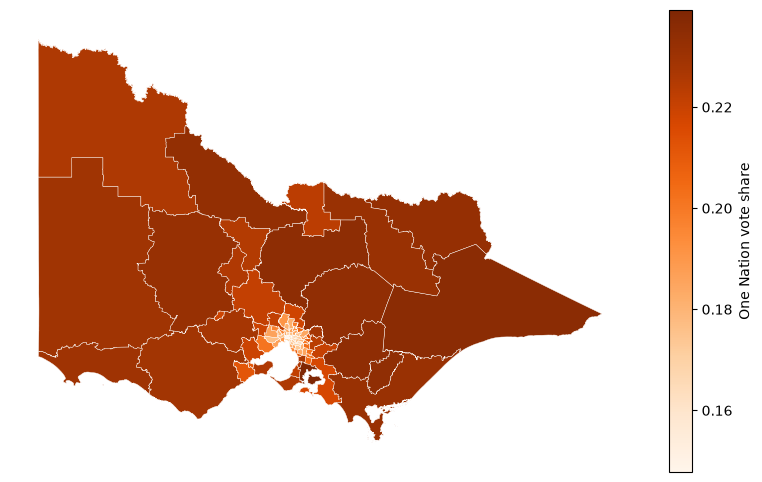

In [25]:
plot_map(
    gdf = electorate_boundaries,
    column = "One Nation",
    cmap = "Oranges",
    label = "One Nation vote share"
)

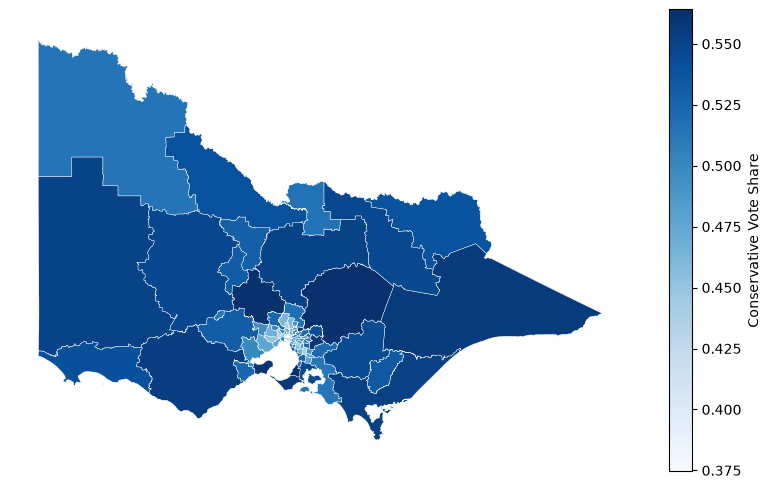

In [26]:
analysis_df = electorate_boundaries.copy()

analysis_df['conservative_share'] = analysis_df['One Nation'] + analysis_df['L/NP']
analysis_df['progressive_share'] = analysis_df['Greens'] + analysis_df['Labor']
analysis_df['conservative_advantage'] = analysis_df['conservative_share'] - analysis_df['progressive_share']

plot_map(
    gdf = analysis_df,
    column = "conservative_share",
    cmap = "Blues",
    label = "Conservative Vote Share"
)

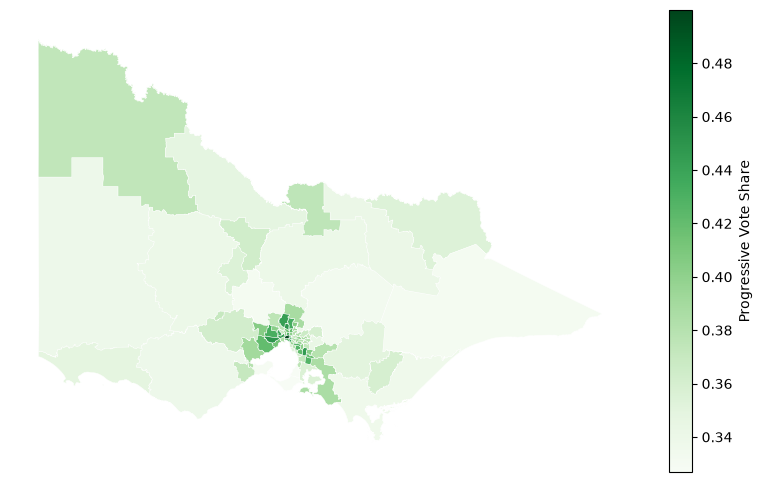

In [27]:
plot_map(
    gdf = analysis_df,
    column = "progressive_share",
    cmap = "Greens",
    label = "Progressive Vote Share"
)

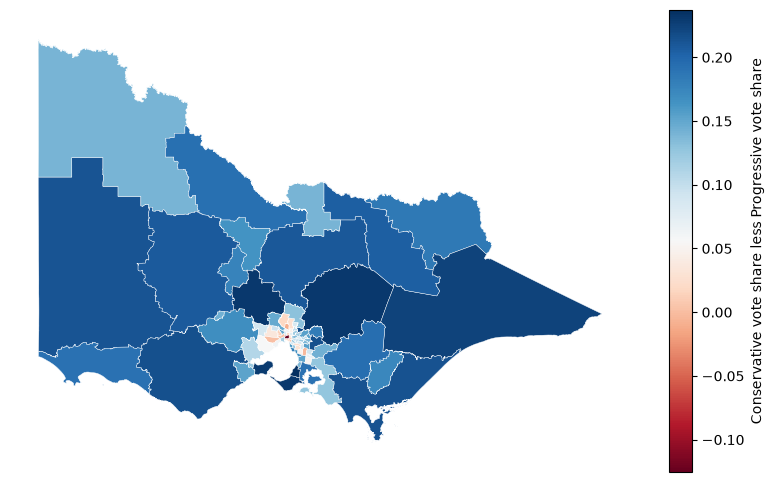

In [28]:
plot_map(
    gdf = analysis_df,
    column = "conservative_advantage",
    cmap = "RdBu",
    label = "Conservative vote share less Progressive vote share"
)

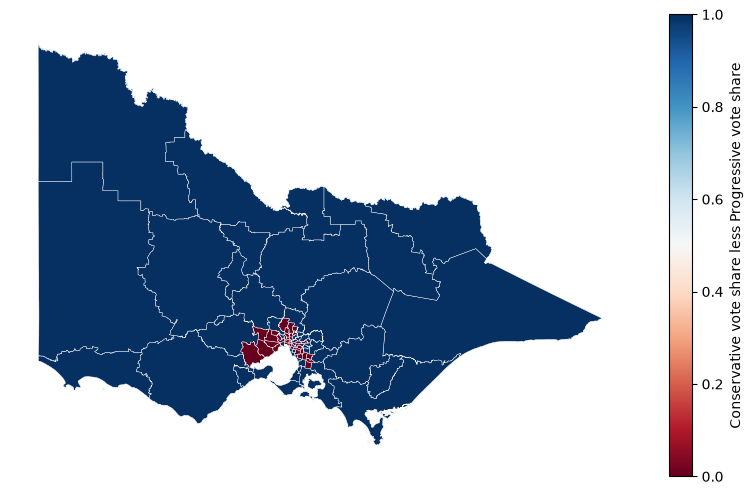

In [29]:
analysis_df['conservative_gt_50'] = 1*(analysis_df['conservative_share'] > 0.5)

plot_map(
    gdf = analysis_df,
    column = "conservative_gt_50",
    cmap = "RdBu",
    label = "Conservative vote share less Progressive vote share"
)

In [30]:
analysis_df['labor_prefs'] = (
    analysis_df['Labor'] 
    + analysis_df['Greens'] * 0.9 
    + analysis_df['One Nation'] * 0.19 
    + analysis_df['Others'] * 0.58
)

analysis_df['lnp_prefs'] = (
    analysis_df['L/NP'] 
    + analysis_df['Greens'] * 0.1 
    + analysis_df['One Nation'] * 0.81 
    + analysis_df['Others'] * 0.42
)

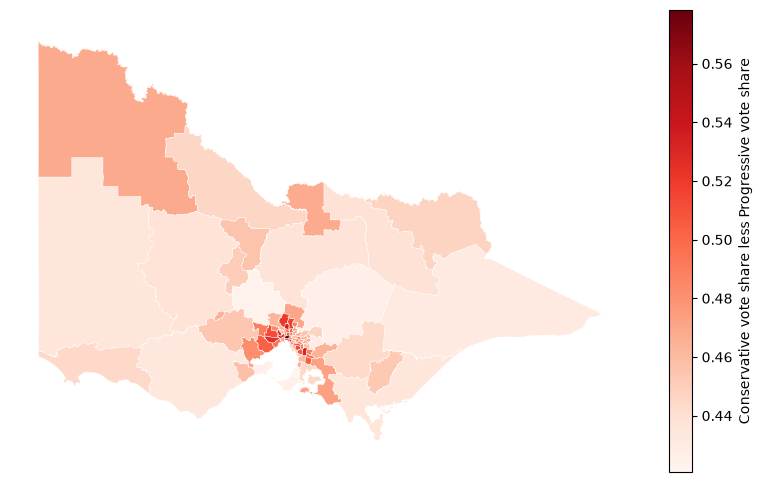

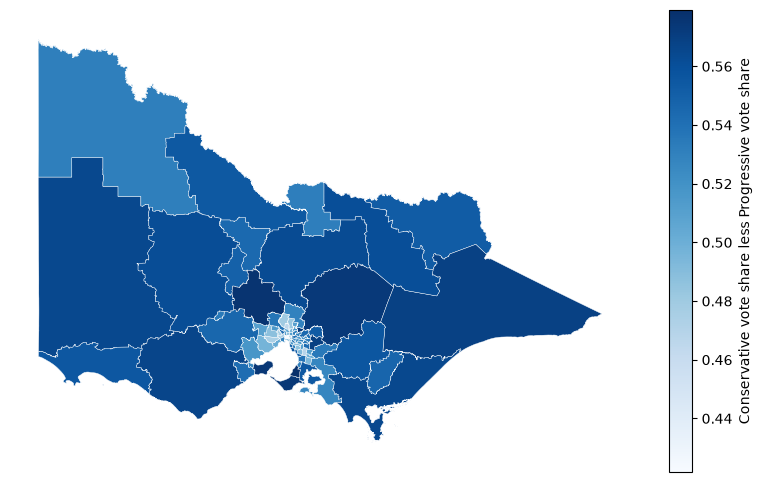

In [31]:
plot_map(
    gdf = analysis_df,
    column = "labor_prefs",
    cmap = "Reds",
    label = "Conservative vote share less Progressive vote share"
)

plot_map(
    gdf = analysis_df,
    column = "lnp_prefs",
    cmap = "Blues",
    label = "Conservative vote share less Progressive vote share"
)

In [32]:
analysis_df['labor_pref_gt_50'] = 1*(analysis_df['labor_prefs'] > 0.5)
analysis_df['lnp_pref_gt_50'] = 1*(analysis_df['lnp_prefs'] > 0.5)

print(analysis_df['labor_pref_gt_50'].sum(), analysis_df['lnp_pref_gt_50'].sum())

19 69


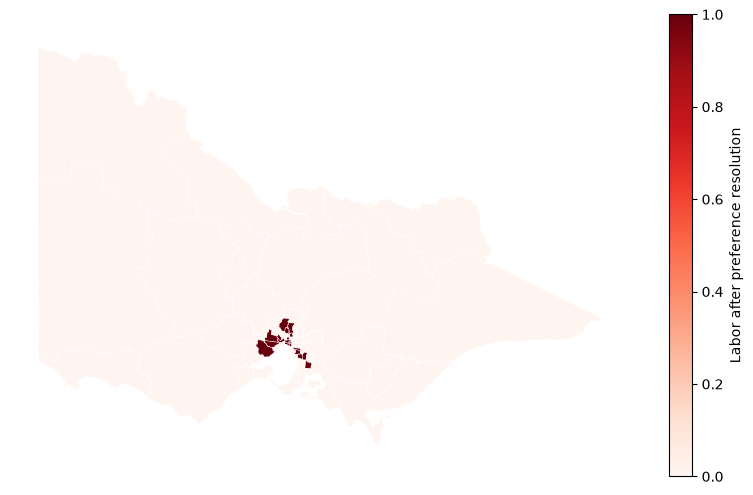

In [33]:
plot_map(
    gdf=analysis_df,
    column = "labor_pref_gt_50",
    cmap = "Reds",
    label = "Labor after preference resolution"
)

In [37]:
from matplotlib.ticker import PercentFormatter

PARTY_COLOURS = {
    'Labor': 'red',
    'L/NP': 'blue',
    'Greens': 'green',
    'One Nation': 'orange',
    'Others': 'grey',
}

def vote_share_by_distance(
        gdf: gpd.GeoDataFrame,
        sed_code: str,
        bands_km: tuple[float, ...] = (5, 10),
        weights: pd.Series | None = None,
        distance_to: str = 'centroid',
        crs: int = 7899,  # GDA2020 / Vicgrid, units in metres
    ) -> pd.DataFrame:
    """Vote share per party for SEDs in distance bands around `sed_code`'s centroid.

    distance_to: 'centroid' measures centroid-to-centroid, 'boundary' measures
    from the target centroid to the nearest edge of each other SED.
    weights: per-SED weights (e.g. adult population) indexed by SED code;
    if None, each SED counts equally.
    """
    parties = list(PARTY_COLOURS)
    gdf = gdf.to_crs(crs)
    target = gdf.loc[gdf['SED_CODE21'] == sed_code]
    if target.empty:
        raise ValueError(f"SED {sed_code} not found")
    origin = target.geometry.centroid.iloc[0]

    others = gdf.loc[gdf['SED_CODE21'] != sed_code].copy()
    geoms = others.geometry.centroid if distance_to == 'centroid' else others.geometry
    others['distance_km'] = geoms.distance(origin) / 1000

    edges = [0, *bands_km, np.inf]
    labels = [f"< {bands_km[0]}km"] + [
        f"{lo}-{hi}km" for lo, hi in zip(bands_km[:-1], bands_km[1:])
    ] + [f"> {bands_km[-1]}km"]
    others['band'] = pd.cut(others['distance_km'], bins=edges, labels=labels, include_lowest=True)

    w = (
        others['SED_CODE21'].map(weights).to_numpy(dtype=float)
        if weights is not None else np.ones(len(others))
    )
    weighted = others[parties].mul(w, axis=0)
    shares = weighted.groupby(others['band'], observed=False).sum().div(
        pd.Series(w, index=others.index).groupby(others['band'], observed=False).sum(), axis=0
    )
    shares['n_seds'] = others.groupby('band', observed=False).size()
    shares.attrs['sed_name'] = target['SED_NAME21'].iloc[0]
    return shares


def plot_vote_share_by_distance(
        gdf: gpd.GeoDataFrame,
        sed_code: str,
        bands_km: tuple[float, ...] = (5, 10),
        weights: pd.Series | None = None,
        distance_to: str = 'centroid',
    ) -> pd.DataFrame:
    shares = vote_share_by_distance(gdf, sed_code, bands_km, weights, distance_to)
    parties = list(PARTY_COLOURS)

    fig, axes = plt.subplots(len(shares), 1, figsize=(8, 3 * len(shares)), sharex=True, sharey=True)
    for ax, (band, row) in zip(axes, shares.iterrows()):
        bars = ax.bar(parties, row[parties], color=[PARTY_COLOURS[p] for p in parties])
        ax.bar_label(bars, labels=[f"{v:.1%}" for v in row[parties]], padding=2)
        ax.set_title(f"{band} ({int(row['n_seds'])} SEDs)", loc='left')
        ax.set_ylabel('Vote share')
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylim(0, shares[parties].to_numpy().max() * 1.2)
    fig.suptitle(f"Vote share by distance from {shares.attrs['sed_name']} ({sed_code})")
    fig.tight_layout()
    return shares


,Labor,L/NP,Greens,One Nation,Others,n_seds
band,,,,,,
< 7km,0.232309,0.284516,0.189085,0.172225,0.121865,6
7-30km,0.258176,0.304882,0.138910,0.185897,0.112134,40
> 30km,0.238290,0.305927,0.126966,0.222492,0.106326,41


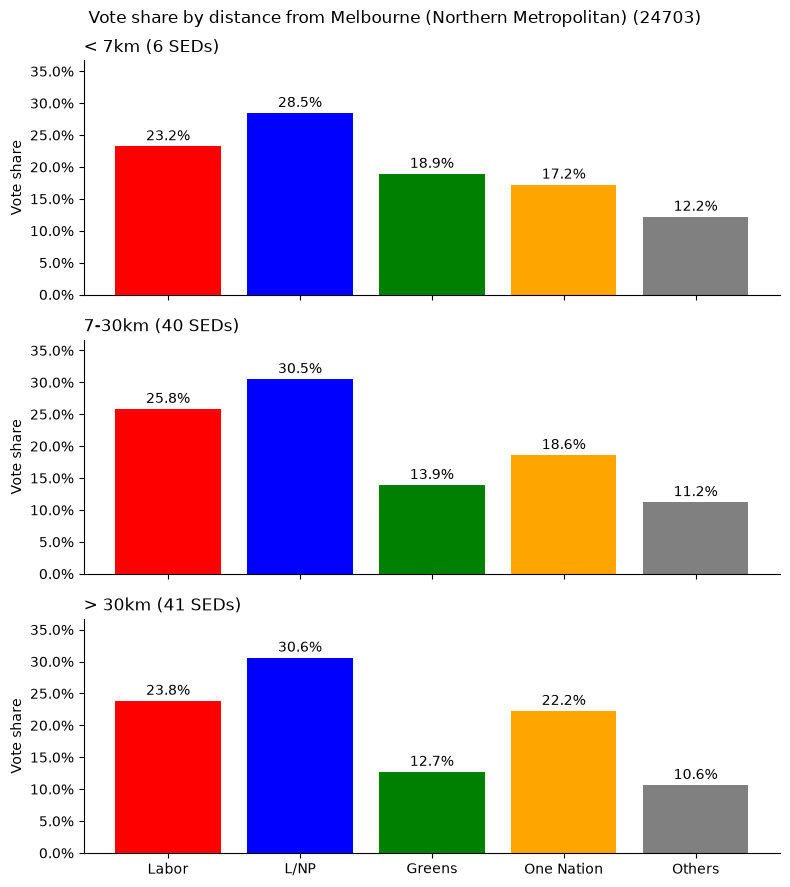

In [44]:
plot_vote_share_by_distance(
    gdf = electorate_boundaries,
    sed_code = "24703",
    bands_km = (7, 30)
)

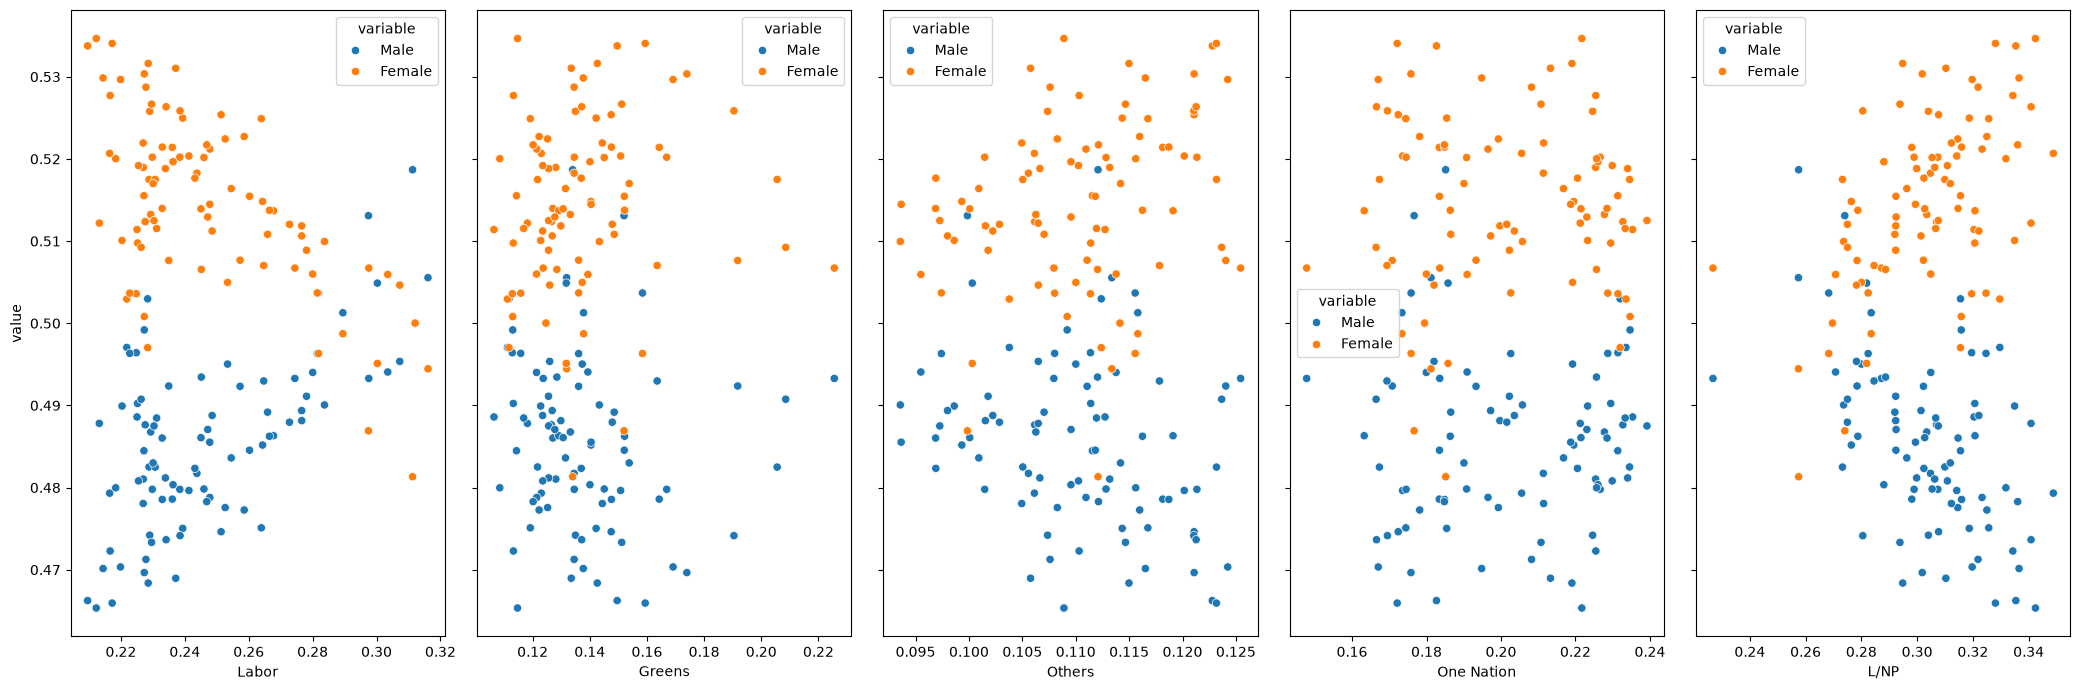

In [56]:
fig, ax = plt.subplots(1, len(PARTY), figsize = (21, 7), sharey = True)
ax = ax.flatten()
to_plot = shares_df.melt(
    id_vars=PARTY,
    # value_vars=EDUCATION

)

for i, p in enumerate(PARTY):

    sns.scatterplot(
        data=to_plot.query("variable.isin(@SEX)"),
        x = p,
        y = "value",
        hue="variable",
        ax=ax[i]
    )
plt.tight_layout()
plt.show()

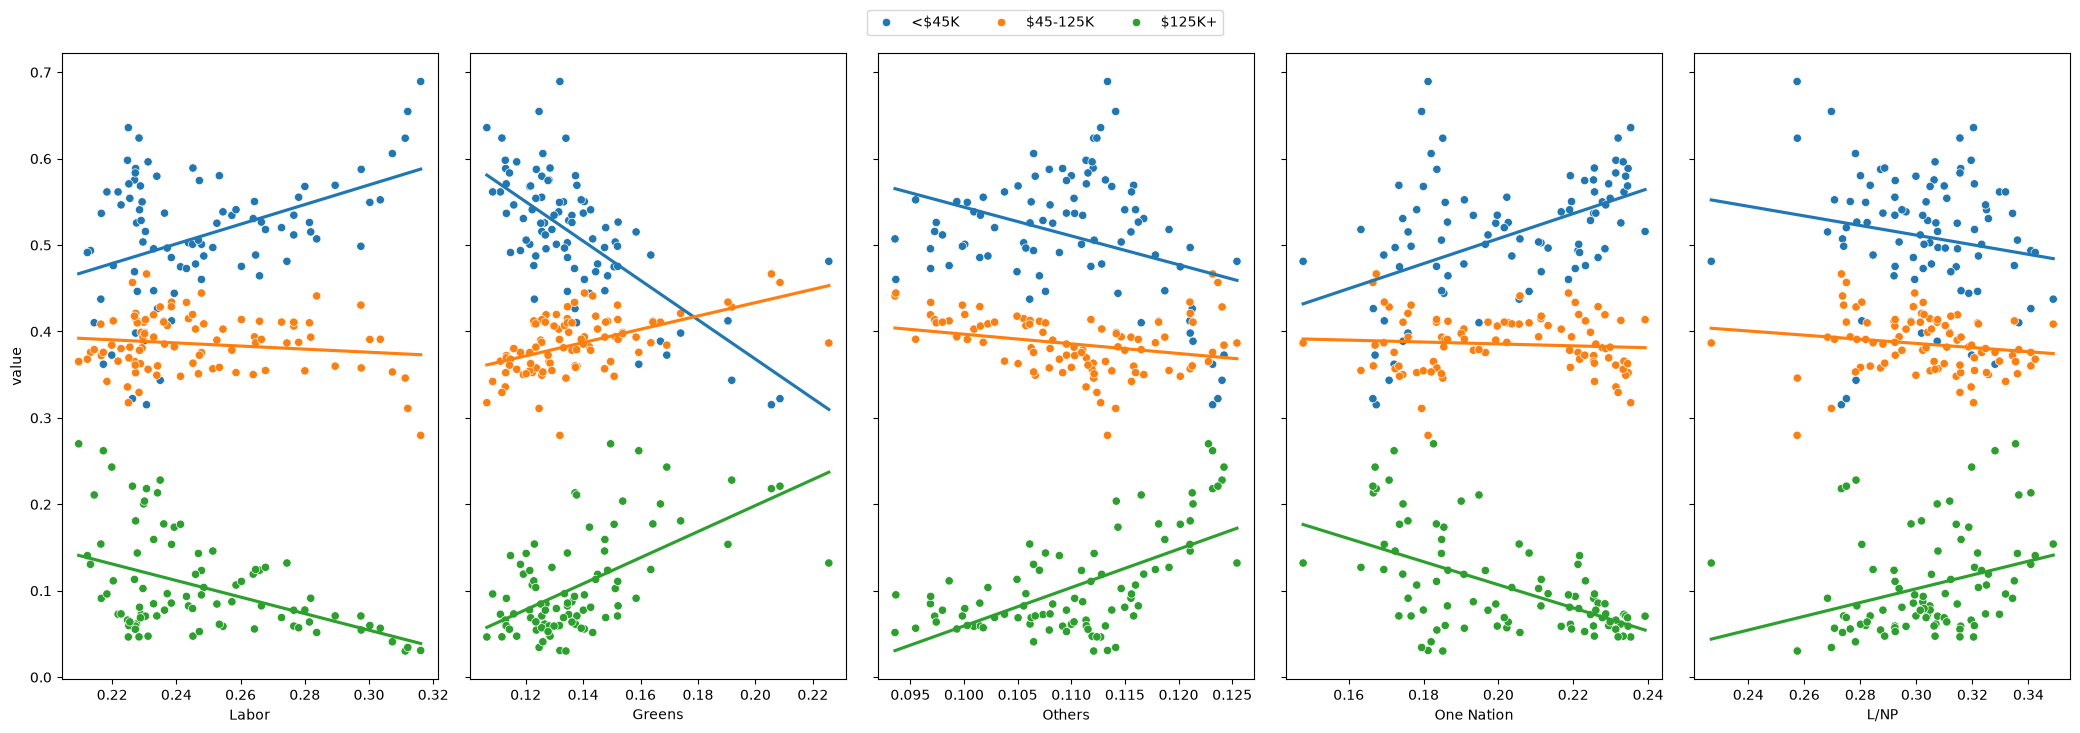

In [60]:
fig, ax = plt.subplots(1, len(PARTY), figsize=(21, 7), sharey=True)
ax = ax.flatten()
to_plot = shares_df.melt(
    id_vars=PARTY,
    # value_vars=EDUCATION
)

data = to_plot.query("variable.isin(@INCOME)")
hues = data["variable"].unique()
palette = dict(zip(hues, sns.color_palette(n_colors=len(hues))))

for i, p in enumerate(PARTY):
    sns.scatterplot(
        data=data,
        x=p,
        y="value",
        hue="variable",
        palette=palette,
        ax=ax[i],
        legend=(i == 0),  # only build legend handles once
    )
    for h in hues:
        sns.regplot(
            data=data[data["variable"] == h],
            x=p,
            y="value",
            scatter=False,
            ci=None,  # drop this to show the confidence band
            color=palette[h],
            ax=ax[i],
        )

handles, labels = ax[0].get_legend_handles_labels()
ax[0].get_legend().remove()

plt.tight_layout()
fig.legend(handles, labels, loc="upper center", ncol=len(hues), bbox_to_anchor=(0.5, 1.05))
plt.show()


In [62]:
electorate_boundaries.to_file("./output.shp", driver="ESRI Shapefile")

C:\Users\61417\AppData\Local\Temp\ipykernel_23460\4272765802.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  electorate_boundaries.to_file("./output.shp", driver="ESRI Shapefile")
c:\Users\61417\Documents\misc_projects\ipf_for_vote_estimation\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'School Education' to 'School Edu'
  ogr_write(
c:\Users\61417\Documents\misc_projects\ipf_for_vote_estimation\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'University Education' to 'University'
  ogr_write(
c:\Users\61417\Documents\misc_projects\ipf_for_vote_estimation\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'TAFE Education' to 'TAFE Educa'
  ogr_write(
c:\Users\61417\Documents\misc_projects\ipf_for_vote_estimation\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered fi

In [34]:
import statsmodels.api as sm

X = shares_df[[col for col in shares_df.columns if col not in PARTY]]
Y = shares_df['One Nation']

model = sm.OLS(Y, X)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:             One Nation   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.870e+04
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          5.30e-126
Time:                        17:17:18   Log-Likelihood:                 548.21
No. Observations:                  88   AIC:                            -1074.
Df Residuals:                      77   BIC:                            -1047.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
School Education           0

C:\Users\61417\AppData\Local\Temp\ipykernel_23460\3356120788.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results = model.fit()


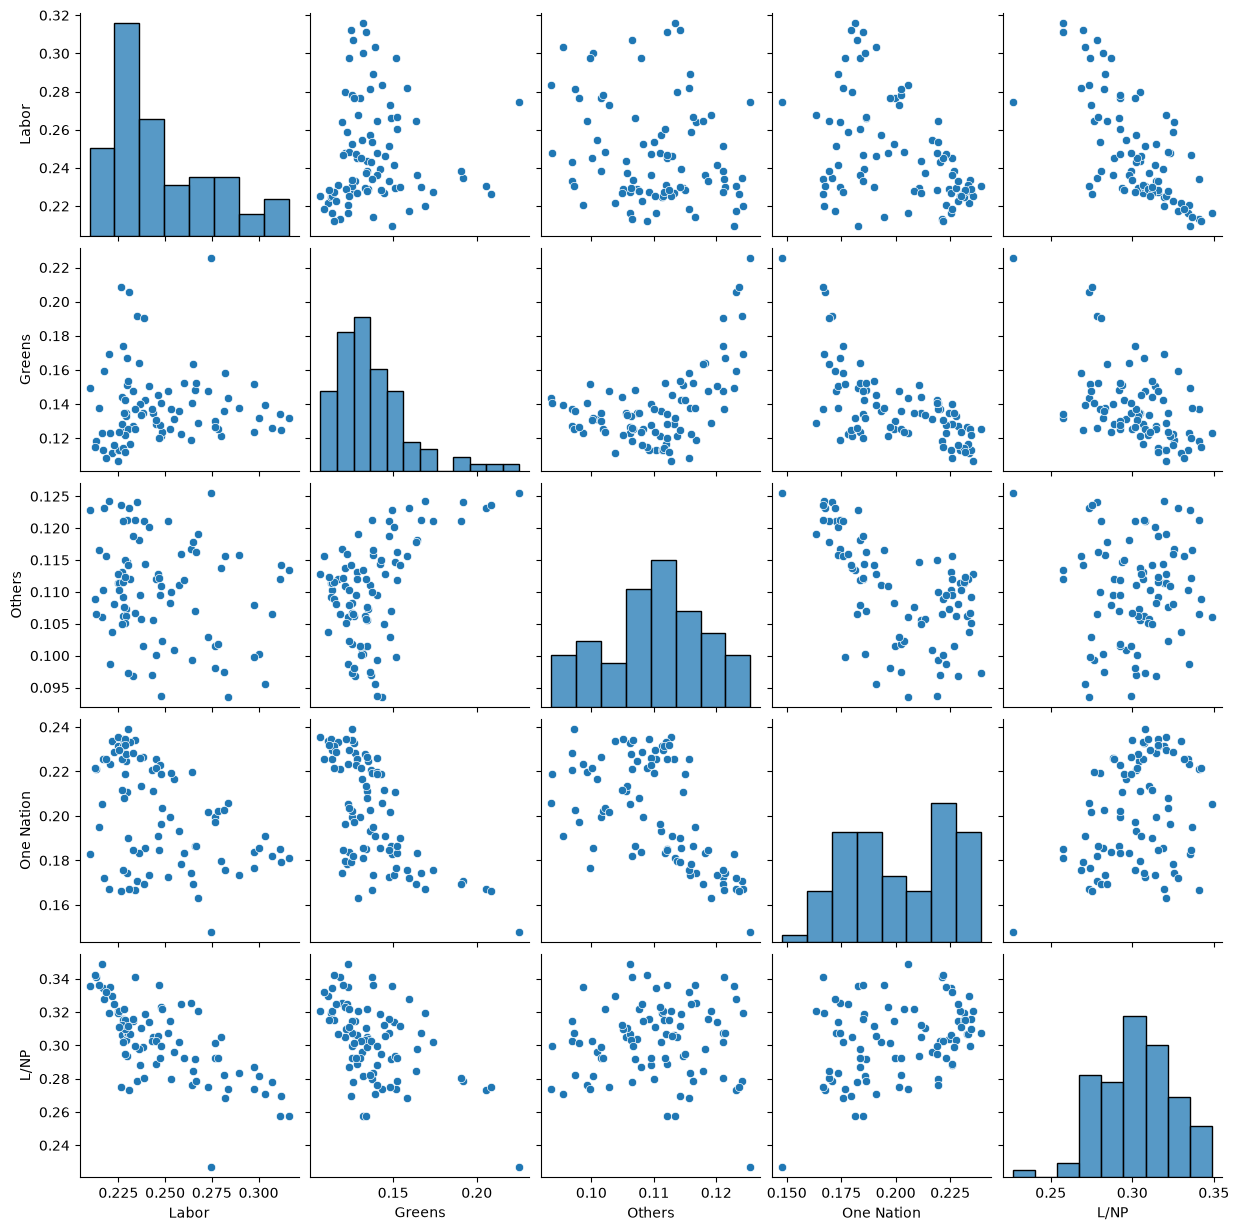

In [35]:
sns.pairplot(shares_df[PARTY])

In [36]:

education_shares_by_region = get_shares_by_region(X, axes = (2, 3, 4, 5, 6, 7), columns=EDUCATION)
age_shares_by_region = get_shares_by_region(X, axes=(1, 3, 4, 5, 6, 7), columns = AGE)


ValueError: No axis named (2, 3, 4, 5, 6, 7) for object type DataFrame

<Axes: xlabel='55+', ylabel='Labor'>

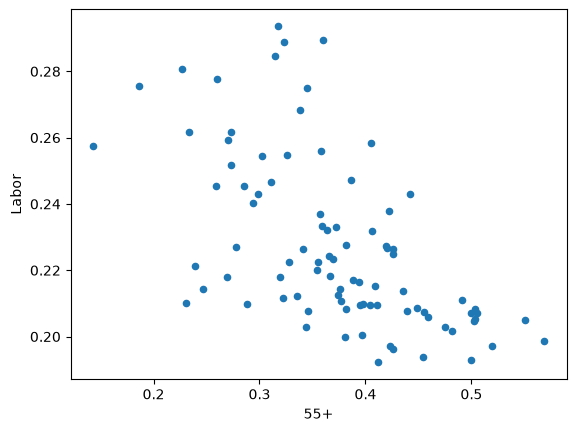

In [ ]:
age_shares_by_region.merge(vote_shares_by_region, on='SED_CODE_2021').plot(kind='scatter', y='Labor', x='55+')

<Axes: xlabel='University Education', ylabel='One Nation'>

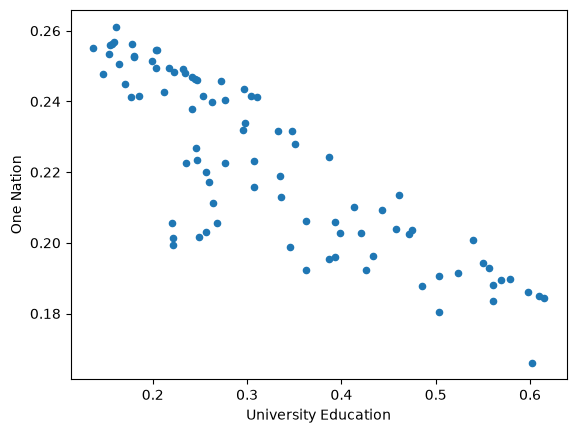

In [ ]:
education_shares_by_region.merge(vote_shares_by_region, on='SED_CODE_2021').plot(kind='scatter', y='One Nation', x='University Education')

In [ ]:
votes = X.sum(axis=(1, 2, 3, 4, 5, 6))
probs_by_region = pd.DataFrame(
    votes / votes.sum(axis=1, keepdims=True),
    index=pd.Index([sed.replace('SED', '') for sed in SEDS], name='SED_CODE_2021'),
    columns=PARTY
)

probs_by_region

,Labor,Greens,Others,One Nation,L/NP
SED_CODE_2021,,,,,
20106,0.230122,0.170233,0.104483,0.199209,0.295953
20207,0.227072,0.136699,0.114365,0.201814,0.320050
20302,0.230873,0.121942,0.096082,0.234973,0.316130
20401,0.226919,0.119573,0.096793,0.234472,0.322243
20508,0.221399,0.089720,0.088477,0.254976,0.345428
...,...,...,...,...,...
28408,0.233769,0.128002,0.085401,0.246050,0.306778
28507,0.237410,0.147632,0.101540,0.214469,0.298949
28607,0.217695,0.127134,0.103236,0.217278,0.334657


In [ ]:
import geopandas as gpd

electorate_boundaries = (
    gpd.read_file('./data/spatial/SED_2021_AUST_GDA2020_SHP/SED_2021_AUST_GDA2020.shp')
    .query('STE_NAME21=="Victoria"')
    .merge(probs_by_region, left_on = 'SED_CODE21', right_on = 'SED_CODE_2021')
)

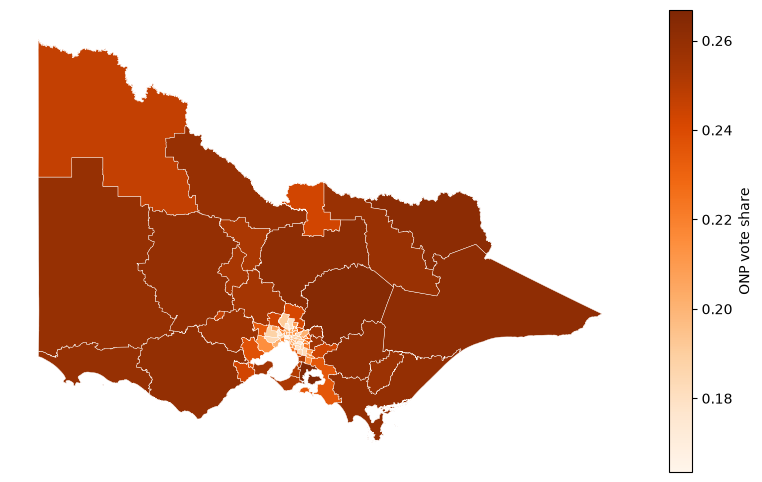

: 

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
electorate_boundaries.plot(
    column='One Nation',          # the column that sets the colour
    cmap='Oranges',
    legend=True,
    legend_kwds={'label': 'ONP vote share', 'shrink': 0.6},
    edgecolor='white',
    linewidth=0.3,
    missing_kwds={'color': 'lightgrey'},   # SEDs with no match show grey
    ax=ax,
)
ax.set_axis_off()

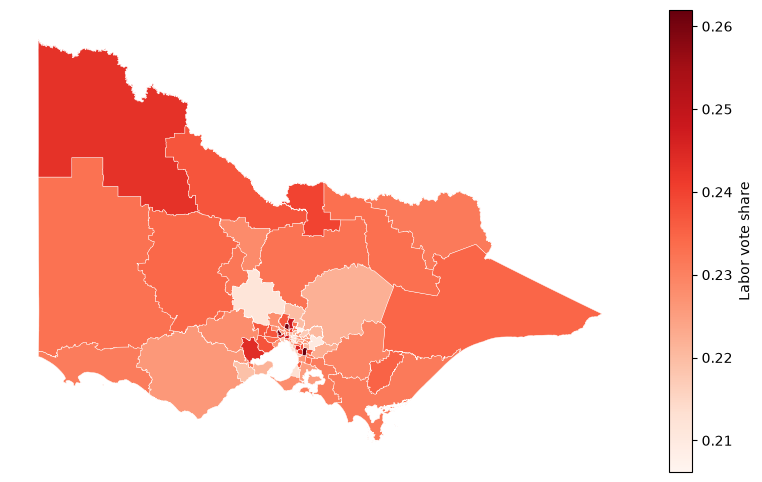

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
electorate_boundaries.plot(
    column='Labor',          # the column that sets the colour
    cmap='Reds',
    legend=True,
    legend_kwds={'label': 'Labor vote share', 'shrink': 0.6},
    edgecolor='white',
    linewidth=0.3,
    missing_kwds={'color': 'lightgrey'},   # SEDs with no match show grey
    ax=ax,
)
ax.set_axis_off()

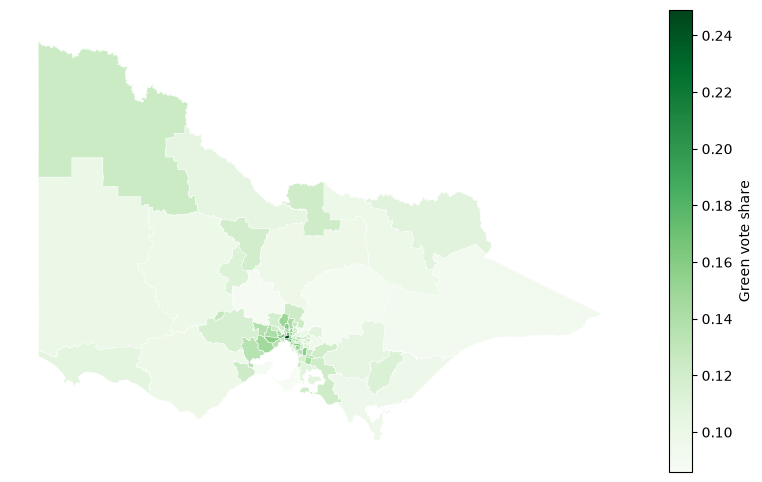

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
electorate_boundaries.plot(
    column='Greens',          # the column that sets the colour
    cmap='Greens',
    legend=True,
    legend_kwds={'label': 'Green vote share', 'shrink': 0.6},
    edgecolor='white',
    linewidth=0.3,
    missing_kwds={'color': 'lightgrey'},   # SEDs with no match show grey
    ax=ax,
)
ax.set_axis_off()

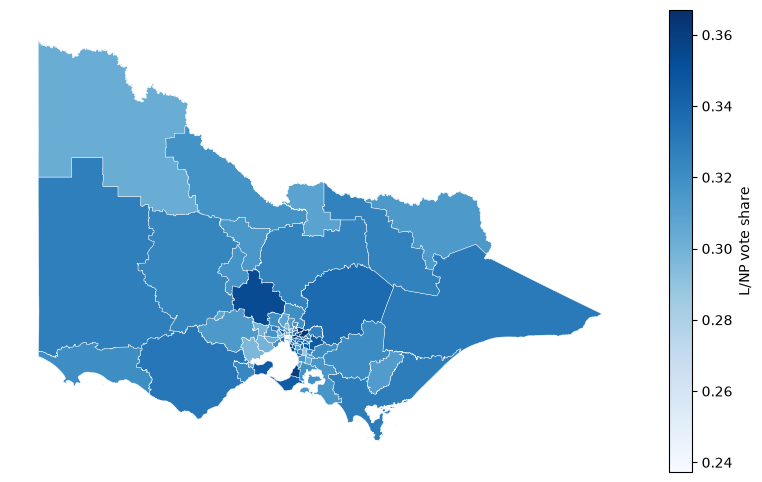

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
electorate_boundaries.plot(
    column='L/NP',          # the column that sets the colour
    cmap='Blues',
    legend=True,
    legend_kwds={'label': 'L/NP vote share', 'shrink': 0.6},
    edgecolor='white',
    linewidth=0.3,
    missing_kwds={'color': 'lightgrey'},   # SEDs with no match show grey
    ax=ax,
)
ax.set_axis_off()

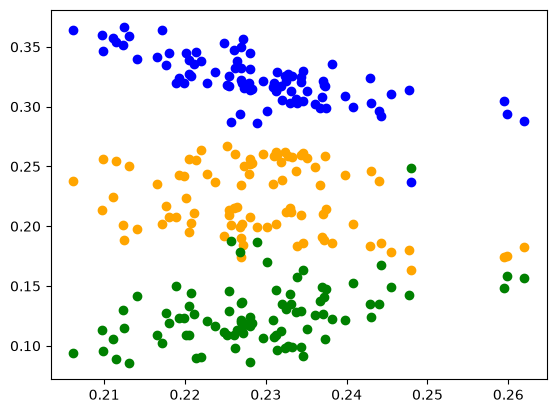

In [ ]:
plt.scatter(electorate_boundaries['Labor'], electorate_boundaries['One Nation'], c = 'orange', label='one nation')
plt.scatter(electorate_boundaries['Labor'], electorate_boundaries['L/NP'], c = 'blue', label='Libs')
plt.scatter(electorate_boundaries['Labor'], electorate_boundaries['Greens'], c = 'green', label='Greens')
